# ENTREGABLE FINAL
## Realizado por: 
### -Rubén Del Valle Carrillo, 52023939D
### -Ángel González De Santos, 54201820C

In [ ]:
# Descargamos los dos ficheros desde el servidor para procesarlos.
# Si se va a usar Colab para la realización de las prácticas, se recomienda descargarlo en la cuenta de Drive para no tener que descargarlos continuamente.
#
# Ficheros:
#   - RS_2025.zst: Submissions (~9,2 GB) - Contiene los posts o hilos de los subreddits seleccionados
#   - RC_2025.zst: Comments (~55 GB) - Contiene todos los comentarios de dichas submissions
#   - RS_OpinionesPolemicas2025.zst: Submissions (~5,6 MB) - Contiene los posts o hilos del subreddit "OpinionesPolemicas"
#   - RC_OpinionesPolemicas2025.zst: Comments (~22,5 GB) - Contiene todos los comentarios de las submissions de "OpinionesPolemicas"
#
# Nota: La descarga puede tardar varios minutos dependiendo de la conexión.
# Una vez descargados, los ficheros se guardarán en el directorio de trabajo actual.

!wget --no-check-certificate  https://valencia.inf.um.es/valencia-plne/RS_2025.zst
!wget --no-check-certificate  https://valencia.inf.um.es/valencia-plne/RC_2025.zst

submissions_file = "RS_2025.zst"
comments_file = "RC_2025.zst"

#!wget --no-check-certificate https://valencia.inf.um.es/valencia-plne/RS_OpinionesPolemicas2025.zst
#!wget --no-check-certificate https://valencia.inf.um.es/valencia-plne/RC_OpinionesPolemicas2025.zst

#submissions_file = "RS_OpinionesPolemicas2025.zst"
#comments_file = "RC_OpinionesPolemicas2025.zst"

--2026-05-01 08:13:10--  https://valencia.inf.um.es/valencia-plne/RS_2025.zst
Resolving valencia.inf.um.es (valencia.inf.um.es)... 155.54.204.133
Connecting to valencia.inf.um.es (valencia.inf.um.es)|155.54.204.133|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 9875477495 (9.2G) [application/zstd]
Saving to: ‘RS_2025.zst’

RS_2025.zst         100%[===================>]   9.20G  26.5MB/s    in 6m 8s   

2026-05-01 08:19:19 (25.6 MB/s) - ‘RS_2025.zst’ saved [9875477495/9875477495]

--2026-05-01 08:19:19--  https://valencia.inf.um.es/valencia-plne/RC_2025.zst
Resolving valencia.inf.um.es (valencia.inf.um.es)... 155.54.204.133
Connecting to valencia.inf.um.es (valencia.inf.um.es)|155.54.204.133|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 58652864239 (55G) [application/zstd]
Saving to: ‘RC_2025.zst’

RC_2025.zst         100%[=========

In [ ]:
#!/usr/bin/env python3
"""
=====================
Este ejemplo procesa archivos de un volcado de Reddit en formato .zst para extraer
submissions y sus comentarios de un subreddit específico.
"""

import zstandard as zstd
import json
import argparse
import io
import sys
from pathlib import Path
from datetime import datetime, UTC


def stream_zst_file(filepath):
    """
    Genera objetos JSON línea por línea desde un archivo .zst
    """
    dctx = zstd.ZstdDecompressor(max_window_size=2**31)

    with open(filepath, 'rb') as fh:
        with dctx.stream_reader(fh) as reader:
            text_stream = io.TextIOWrapper(reader, encoding='utf-8', errors='ignore')

            for line in text_stream:
                line = line.strip()
                if not line:
                    continue
                try:
                    yield json.loads(line)
                except json.JSONDecodeError:
                    continue


def extract_submissions(filepath, subreddit, n_submissions=3, min_comments=250):
    """
    Extrae las primeras N submissions de un subreddit con al menos min_comments comentarios.
    Captura TODOS los atributos del dump.
    ¡OJO! Para la práctica 2 se deberá realizar un procesamiento de qué subreddits se pretenden seleccionar
    teniendo en cuenta distintas características de los posts como la fecha, información sobre los sumbissions, etc.
    Además, no se deberán almacenar todos los atributos, sino los más relevantes para los usuarios.
    """
    submissions = []
    subreddit_lower = subreddit.lower()

    print(f"🔍 Buscando submissions en r/{subreddit} con ≥{min_comments} comentarios...")

    count = 0
    scanned = 0

    for obj in stream_zst_file(filepath):
        if obj.get('subreddit', '').lower() != subreddit_lower:
            continue

        scanned += 1
        num_comments = obj.get('num_comments', 0) or 0

        if num_comments < min_comments:
            continue

        # Copiar TODOS los atributos originales
        submission = obj.copy()

        # Añadir campos calculados
        submission['name'] = f"t3_{obj.get('id')}"
        submission['created_datetime'] = datetime.fromtimestamp(
            obj.get('created_utc', 0), UTC
        ).isoformat() if obj.get('created_utc') else None
        submission['comments'] = []  # Se llenará después con los comentarios

        submissions.append(submission)
        count += 1
        print(f"  ✓ [{count}/{n_submissions}] ({num_comments} comments) {submission.get('title', '')[:50]}...")

        if count >= n_submissions:
            break

    print(f"\n  Escaneadas: {scanned} del subreddit")
    print(f"  Encontradas: {len(submissions)} con ≥{min_comments} comentarios\n")
    return submissions


def extract_comments_for_submissions(filepath, submissions, num_comments=10):
    """
    Extrae los primeros N comentarios para cada submission.
    Captura TODOS los atributos del dump.
    """
    if num_comments <= 0:
        print("⏭️  num_comments=0, saltando búsqueda de comentarios")
        return

    if not submissions:
        print("⏭️  Sin submissions")
        return

    submission_map = {s['name']: s for s in submissions}
    comment_count = {s['name']: 0 for s in submissions}
    pending = set(submission_map.keys())

    print(f"🔍 Buscando hasta {num_comments} comentarios por submission...")

    total_comments = 0

    for obj in stream_zst_file(filepath):
        link_id = obj.get('link_id')

        if link_id not in pending:
            continue

        # Copiar TODOS los atributos originales
        comment = obj.copy()

        # Añadir campos calculados
        comment['name'] = f"t1_{obj.get('id')}"
        comment['created_datetime'] = datetime.fromtimestamp(
            obj.get('created_utc', 0), UTC
        ).isoformat() if obj.get('created_utc') else None

        submission_map[link_id]['comments'].append(comment)
        comment_count[link_id] += 1
        total_comments += 1

        if comment_count[link_id] >= num_comments:
            pending.discard(link_id)
            if not pending:
                break

    print(f"  Total: {total_comments} comentarios encontrados\n")
    for s in submissions:
        print(f"  📝 \"{s.get('title', '')[:50]}...\" → {len(s['comments'])} comentarios")

# EJERCICIO 1. Creación del corpus y procesamiento léxico

In [ ]:
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 9.2 MB/s eta 0:00:00


In [ ]:
import sys
from datetime import datetime

#Creamos una lista de subreddits a procesar y el número de submissions a extraer por cada uno.
subreddit_list = ["soccer", "nba", "ForTNiteBR", "Eldenring", " unpopularopinion", "wallstreetbets"]
num_submissions_target = 40

print(f"{'='*60}")
print(f"Subreddits a procesar: {subreddit_list}")
print(f"{'='*60}\n")


# 3. Crear resultado final
def resultado(nombre_subreddit, submissions_file = submissions_file, comments_file= comments_file):
    subs_extraidas = extract_submissions(submissions_file, nombre_subreddit, num_submissions_target)
    extract_comments_for_submissions(comments_file, subs_extraidas, num_comments=40)
    result = {
    'subreddits_procesados': nombre_subreddit,
    'extraction_date': datetime.utcnow().isoformat(),
    'num_total_submissions': len(subs_extraidas),
    'total_comments':sum(len(s.get('comments', [])) for s in subs_extraidas),
    'submissions': subs_extraidas
    }
    # 4. Mostrar Resumen
    print(f"\n{'='*60}")
    print(f"✅ Extracción completada:")
    print(f"   - {result['num_total_submissions']} submissions totales de subreddit {nombre_subreddit}")
    print(f"   - {result['total_comments']} comentarios totales")
    print(f"{'='*60}")
    return result

result_soccer = resultado('soccer')
result_nba = resultado('nba')
result_fortnite = resultado('FortNiteBR')
result_eldenring = resultado('eldenring')
result_unpopularopinion= resultado('unpopularopinion')
result_wallstreetbets= resultado('wallstreetbets')


Subreddits a procesar: ['soccer', 'nba', 'ForTNiteBR', 'Eldenring', ' unpopularopinion', 'wallstreetbets']

🔍 Buscando submissions en r/nba con ≥250 comentarios...
  ✓ [1/40] (808 comments) GAME THREAD: Minnesota Timberwolves (17-14) @ Okla...
  ✓ [2/40] (689 comments) GAME THREAD: Cleveland Cavaliers (28-4) @ Los Ange...
  ✓ [3/40] (277 comments) [Post Game Thread] The Oklahoma City Thunder (27-5...
  ✓ [4/40] (457 comments) [Post Game Thread] The Cleveland Cavaliers (29-4) ...
  ✓ [5/40] (552 comments) [McMenamin] JJ Redick says you have to play “close...
  ✓ [6/40] (587 comments) At a cost of $408M and a 15-17 record, the Phoenix...
  ✓ [7/40] (373 comments) 'Unguardable' SGA is MVP, Wolves' Anthony Edwards ...
  ✓ [8/40] (310 comments) [Greg Finberg] Jordan Poole this season: 21.3 PPG ...
  ✓ [9/40] (675 comments) Bryce James has committed to the University of Ari...
  ✓ [10/40] (554 comments) [Highlight] Jarrett Allen in his post game intervi...
  ✓ [11/40] (396 comments) GAME THR

/tmp/ipykernel_15239/1429531279.py:19: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'extraction_date': datetime.utcnow().isoformat(),


  ✓ [3/40] (338 comments) Banned for two weeks for no reason and then got th...
  ✓ [4/40] (253 comments) What are the best (and worst) skins released in 20...
  ✓ [5/40] (311 comments) Is Tank Penny in BR? I only see her in Save the Wo...
  ✓ [6/40] (334 comments) Looking back I actually feel that 2024 was a very ...
  ✓ [7/40] (263 comments) Which contrail is your go to for skins without one...
  ✓ [8/40] (394 comments) my collab wishlist...
  ✓ [9/40] (293 comments) I hate superhero skins...
  ✓ [10/40] (290 comments) This video is such a statement ...
  ✓ [11/40] (706 comments) Which shotgun this season is your favorite?...
  ✓ [12/40] (795 comments) Anyone else tired of rappers and sports people in ...
  ✓ [13/40] (338 comments) Are you fucking serious ...
  ✓ [14/40] (445 comments) Every time i see this skin i wanna throw my contro...
  ✓ [15/40] (809 comments) Giving away 2 codes for dc gliders...
  ✓ [16/40] (281 comments) Hello all, I have an extra 1500 Vbucks and am look...
 

El resultado de esto, es que ahora tenemos seis diccionarios diferentes (uno para cada subreddit). Sin embargo, estos se encuentran con muchos comentarios erroneos y columnas innecesarias para nuestro analisi, por lo que es necesario limpiar dichos diccionarios.

In [ ]:
import re
import emoji

#Con etsa funcion, observaremos si un comentario es válido o no, es decir, si tiene contenido real o solo enlaces, emojis o emails.
def es_comentario_valido(texto):
    if not texto or not isinstance(texto, str):
        return False

    # 1. Limpieza básica para evaluar contenido real
    texto_limpio = texto.strip()

    # 2. Expresiones regulares para detectar URLs y Gmails
    regex_url = r'https?://\S+|www\.\S+'
    regex_email = r'[a-zA-Z0-9._%+-]+@gmail\.com'



    # 3. Eliminar URLs y Emails del texto para ver qué queda

    solo_texto = re.sub(regex_url, '', texto_limpio)
    solo_texto = emoji.replace_emoji(solo_texto, replace='')
    solo_texto = re.sub(regex_email, '', solo_texto).strip()
    # 4. El comentario es válido solo si queda contenido después de quitar URLs/Emails
    return len(solo_texto) > 5



In [ ]:
from math import e
#Con esta funcion, filtraremos unicamente las categorías que nos interesan de cada submission y comentario, además de eliminar aquellos comentarios que no sean válidos según la función anterior.
def filtrar_categorias(subreddit):
    columnas_sub = ("id", "title", "author", "flair", "score", "created_utc", "description", "comments")
    columnas_com = ("id", "author", "body", "score", "created_utc", "is_submitter")



    for submission in subreddit['submissions']:
        # Filtramos la submission: solo las claves que existen y están en nuestra lista
        nueva_sub = {k: submission[k] for k in columnas_sub if k in submission}

        # Filtramos los comentarios dentro de esa submission

        if "comments" in nueva_sub:
            nueva_sub["comments"] = [
                {k: c[k] for k in columnas_com if k in c}
                for c in nueva_sub["comments"]
            ]
            for c in nueva_sub['comments']:
              if es_comentario_valido(c['body']):
                continue
              else:
                nueva_sub['comments'].remove(c)
        subreddit['submissions'][subreddit['submissions'].index(submission)] = nueva_sub
        subreddit['total_comments'] = sum(len(s.get('comments', [])) for s in subreddit['submissions'])
    return subreddit

# Genermaos el nuevo resultado filtrado con las categorías que nos interesan y eliminando los comentarios no válidos.
result_soccer_filtrado = filtrar_categorias(result_soccer)
result_nba_filtrado = filtrar_categorias(result_nba)
result_fortnite_filtrado = filtrar_categorias(result_fortnite)
result_elden_filtrado = filtrar_categorias(result_eldenring)
result_unpopular_filtrado = filtrar_categorias(result_unpopularopinion)
result_wallstreet_filtrado = filtrar_categorias(result_wallstreetbets)


Ya tenemos los diccionarios limpiados. El siguiente paso sera corregir aquellos comentarios que esten mal escritos o con faltas de ortografía. La correción la haremos con SymSpell.

In [ ]:
import pkg_resources
from symspellpy import SymSpell

# Inicializar con distancia 2 para inglés
sym_spell = SymSpell(max_dictionary_edit_distance=2, prefix_length=7)

# Cargar el diccionario (en ingles) incluido en la librería
dictionary_path = pkg_resources.resource_filename(
    "symspellpy", "frequency_dictionary_en_82_765.txt"
)

sym_spell.load_dictionary(dictionary_path, term_index=0, count_index=1)
def corregir_symspell(frase):
    # Validación de seguridad
    if not frase or not isinstance(frase, str):
        return ""

    try:
        # lookup_compound devuelve una LISTA de objetos SuggestItem
        sugs = sym_spell.lookup_compound(frase, max_edit_distance=2)

        # sugs[0].term extrae el texto corregido
        if sugs:
            return sugs[0].term
        return frase
    except Exception:
        return frase

def corregir_texto_comentarios(subreddit_data):
    for s in subreddit_data['submissions']:
        # Guardamos el procesado en un campo nuevo
        s['title_preprocessed'] = corregir_symspell(s.get('title', ""))

        for c in s.get('comments', []):
            # Guardamos el procesado en un campo nuevo
            c['body_preprocessed'] = corregir_symspell(c.get('body', ""))

    return subreddit_data

# Ejecución
result_soccer_corregido = corregir_texto_comentarios(result_soccer_filtrado)
result_nba_corregido = corregir_texto_comentarios(result_nba_filtrado)
result_fortnite_corregido = corregir_texto_comentarios(result_fortnite_filtrado)
result_elden_corregido = corregir_texto_comentarios(result_elden_filtrado)
result_unpopular_corregido = corregir_texto_comentarios(result_unpopular_filtrado)
result_wallstreet_corregido = corregir_texto_comentarios(result_wallstreet_filtrado)


Con esto ya tendriamos los diccionarios corregidos y preprocesados. 

In [ ]:
#Guardar resultados
import json
from google.colab import drive

# Montar Drive
drive.mount('/content/drive')

# Guardarlo como JSON en Drive
with open("/content/drive/MyDrive/plne/entregable/result_wallstreet_corregido", "w", encoding="utf-8") as f:
    json.dump(result_wallstreet_corregido, f, ensure_ascii=False, indent=2)


print("✅ Guardado en Google Drive como result.json")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Guardado en Google Drive como result.json


In [ ]:
with open("/content/drive/My Drive/result.json", "r", encoding="utf-8") as f:
    result = json.load(f)

print(result)

# EJERCICIO 2. Clasificador de comentarios en subreddits

In [ ]:
#Creamos la descarga de los json anteriores para poder ahorrarnos descargar el fichero de 50 GB a cada interacción con el kernel. Esto aparecera en cada ejercicio como cominenzo de este

In [ ]:
import json
from google.colab import drive
drive.mount('/content/drive')


with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_wallstreet_corregido", "r", encoding="utf-8") as f:
    result_walstreet_corregido = json.load(f)



Mounted at /content/drive


In [ ]:
with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_soccer_corregido", "r", encoding="utf-8") as f:
    result_soccer_corregido = json.load(f)

with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_nba_corregido", "r", encoding="utf-8") as f:
    result_nba_corregido = json.load(f)

with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_unpopular_corregido", "r", encoding="utf-8") as f:
    result_unpopular_corregido = json.load(f)

with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_fortnite_corregido", "r", encoding="utf-8") as f:
    result_fortnite_corregido = json.load(f)

with open("/content/drive/MyDrive/lenguaje_natural/entregable/datos/result_elden_corregido", "r", encoding="utf-8") as f:
    result_elden_corregido = json.load(f)


In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

subreddit_list = [result_elden_corregido, result_fortnite_corregido, result_walstreet_corregido, result_unpopular_corregido, result_nba_corregido, result_soccer_corregido]
data = [] #Lista de diccionarios con los comentarios y su id subreddit al que pertenecen

for subreddit in subreddit_list: #Recorremos todos los subreddits de la lista
  etiqueta_subreddit = subreddit.get("subreddits_procesados")

  for submission in subreddit.get("submissions", []):#Dentro de los subreddits recoremos sus submissions y recogemos las ids de cada submission
      id = submission.get("id")

      for comment in submission.get("comments", []):#Dentro de cada submission recorre sus comentarios y de ellos recoge el cuerpo ya procesado y el autor
          body = comment.get("body_preprocessed")
          author = comment.get("author")

          # Filtramos el ruido: AutoModerator y comentarios borrados
          if body and body != "[removed]" and author != "AutoModerator":
              data.append({
                  "id": id,
                  "body": body,
                  "subreddit": etiqueta_subreddit
              })

df = pd.DataFrame(data)

# test_size=0.2 separa el 20% de los HILOS (no de los comentarios individuales) para test
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

#gss nos devuelve un iterador que divide el dataframe en entrenamiento y test en función de id, por eso usamos un for
for idx_tr, idx_te in gss.split(df['body'], df['subreddit'], groups=df['id']):
    train_idx = idx_tr
    test_idx = idx_te
    break #Solo queremos una división asi que paramos a la primera

#gss nos devuelve el indice de las filas de cada conjunto asi que en este paso los definimos por completo
train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

#dividimos en X e Y cuando ya hemos terminado la partición
x_train = train_df['body']
y_train = train_df['subreddit']

x_test = test_df['body']
y_test = test_df['subreddit']



#PRIMER ENFOQUE

No me va BM25.py en el import asi que he tenido que poner el codigo de abajo para que funcione, lo hemos dejado oculto para que ocupe menos espacio




In [ ]:
# @title
#IMPLEMENTACIÓN DEL BM25 - OKAPI
# coding: UTF-8
from __future__ import absolute_import, division, print_function, unicode_literals
import numpy as np
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.feature_extraction.text import _document_frequency
from sklearn.preprocessing import normalize

class BM25Transformer(TfidfTransformer):
    """
    Parameters
    ----------
    use_idf : boolean, optional (default=True)
    k1 : float, optional (default=1.2)
    b : float, optional (default=0.75)
    References
    ----------
    Okapi BM25: a non-binary model - Introduction to Information Retrieval
    http://nlp.stanford.edu/IR-book/html/htmledition/okapi-bm25-a-non-binary-model-1.html
    """
    def __init__(self,k=1.2,b=0.75, norm="l2", use_idf=True, smooth_idf=True,
                 sublinear_tf=False):
        self.k = k
        self.b = b
        ######### tfidf ###########
        self.norm = norm
        self.use_idf = use_idf
        self.smooth_idf = smooth_idf
        self.sublinear_tf = sublinear_tf

    def fit(self, X, y=None):
        """Learn the idf vector (global term weights)

        Parameters
        ----------
        X : sparse matrix, [n_samples, n_features]
            a matrix of term/token counts
        """
        XA = X.toarray()
        self.avdl = XA.sum()/XA.shape[0]

        super().fit(X)
        return self

    def transform(self, X, copy=True):
        """Transform a count matrix to a tf or tf-idf representation.

        Parameters
        ----------
        X : sparse matrix of (n_samples, n_features)
            A matrix of term/token counts.

        copy : bool, default=True
            Whether to copy X and operate on the copy or perform in-place
            operations.

        Returns
        -------
        vectors : sparse matrix of shape (n_samples, n_features)
            Tf-idf-weighted document-term matrix.
        """
        cur_tf =  X.toarray() #[N,M]
        norm_lenght = 1 - self.b + self.b*(X.toarray().sum(-1)/self.avdl) #[N] #N表示数据的条数
        norm_lenght = norm_lenght.reshape([norm_lenght.shape[0],1]) #[N,1]
        X = (self.k+1)*cur_tf /(cur_tf +self.k*norm_lenght)

        if not sp.issparse(X):
            X = sp.csr_matrix(X, dtype=np.float64)

        if self.sublinear_tf:
            np.log(X.data, X.data)
            X.data += 1

        if self.use_idf:
            # idf_ being a property, the automatic attributes detection
            # does not work as usual and we need to specify the attribute
            # name:
            check_is_fitted(self, attributes=["idf_"], msg="idf vector is not fitted")

            # *= doesn't work
            X = X.multiply(self.idf_)

        if self.norm:
            X = normalize(X, norm=self.norm, copy=False)

        return X


## SVM

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
#Comenzamos creando los Pipelines pertencientes al modelo SVM pero con los tres distintos tipos de representación de texto que usaremos [TF-IDF, TF, BM25] y los entrenamos

# Pipeline SVM con TF
clf_svm_tf = Pipeline([
    ('vect', CountVectorizer()),
    ('tf', TfidfTransformer(use_idf=False)),
    ('clf', LinearSVC(random_state=0, tol=1e-5)),
])

# Pipeline SVM con TF-IDF
clf_svm_tfidf = Pipeline([
    ('vect', CountVectorizer()),
    ('tfidf', TfidfTransformer(use_idf=True)),
    ('clf', LinearSVC(random_state=0, tol=1e-5)),
])

# Pipeline SVM con BM25
clf_svm_bm25 = Pipeline([
    ('vect', CountVectorizer()),
    ('bm25', BM25Transformer(k=1.2, b=0.5)),
    ('clf', LinearSVC(random_state=0, tol=1e-5)),
])

# Entrenamiento
clf_svm_tf.fit(x_train, y_train)
clf_svm_tfidf.fit(x_train, y_train)
clf_svm_bm25.fit(x_train, y_train)

Pipeline(steps=[('vect', CountVectorizer()), ('bm25', BM25Transformer(b=0.5)),
                ('clf', LinearSVC(random_state=0, tol=1e-05))])

In [ ]:
#Evaluamos el TF
predicted_tf = clf_svm_tf.predict(x_test)
accuracy_tf = np.mean(predicted_tf == y_test)

print("Resultados TF ----- Accuracy:", accuracy_tf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tf))

# Evaluamos el TFIDF
predicted_tfidf = clf_svm_tfidf.predict(x_test)
accuracy_tfidf = np.mean(predicted_tfidf == y_test)

print("Resultados TFIDF ----- Accuracy:", accuracy_tfidf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tfidf))

# Evaluamos el BM25
predicted_bm25 = clf_svm_bm25.predict(x_test)
accuracy_bm25 = np.mean(predicted_bm25 == y_test)

print("Resultados BM25 ----- Accuracy:", accuracy_bm25)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_bm25))

Resultados TF ----- Accuracy: 0.5534564190639759
                  precision    recall  f1-score   support

      FortNiteBR       0.61      0.42      0.50       463
       eldenring       0.71      0.55      0.62       577
             nba       0.64      0.59      0.62       477
          soccer       0.54      0.62      0.58       310
unpopularopinion       0.27      0.57      0.37       155
  wallstreetbets       0.48      0.61      0.54       347

        accuracy                           0.55      2329
       macro avg       0.54      0.56      0.54      2329
    weighted avg       0.59      0.55      0.56      2329

Resultados TFIDF ----- Accuracy: 0.5693430656934306
                  precision    recall  f1-score   support

      FortNiteBR       0.61      0.44      0.51       463
       eldenring       0.71      0.57      0.63       577
             nba       0.67      0.60      0.63       477
          soccer       0.55      0.64      0.59       310
unpopularopinion       0.

### Vemos que en este caso obtenemos mejores resultados tanto con BM25 como con TF-IDF con un 57% de accuracy

<Axes: >

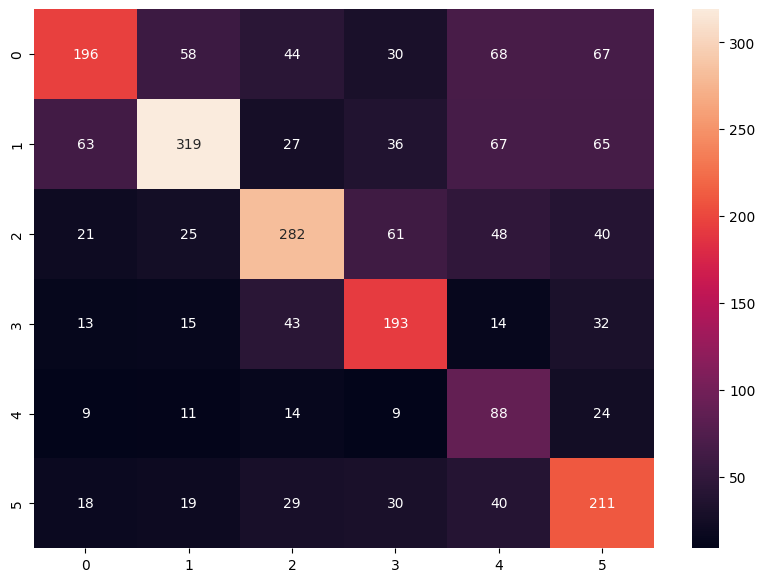

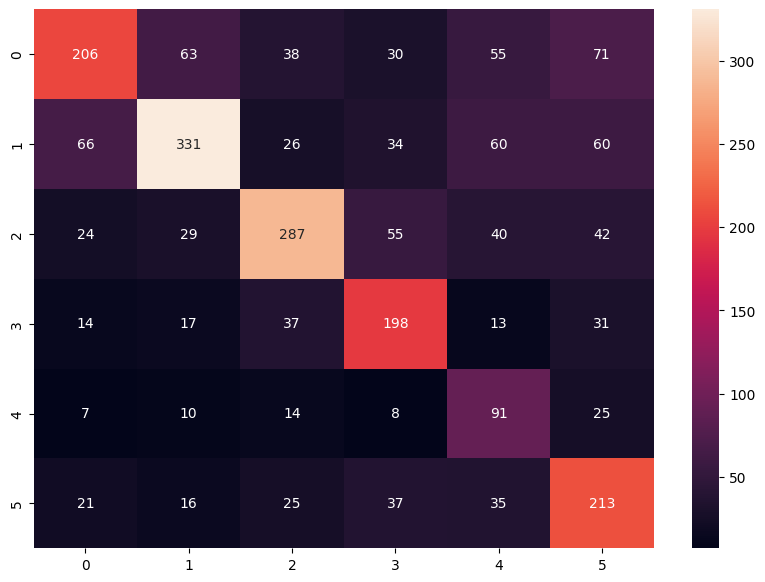

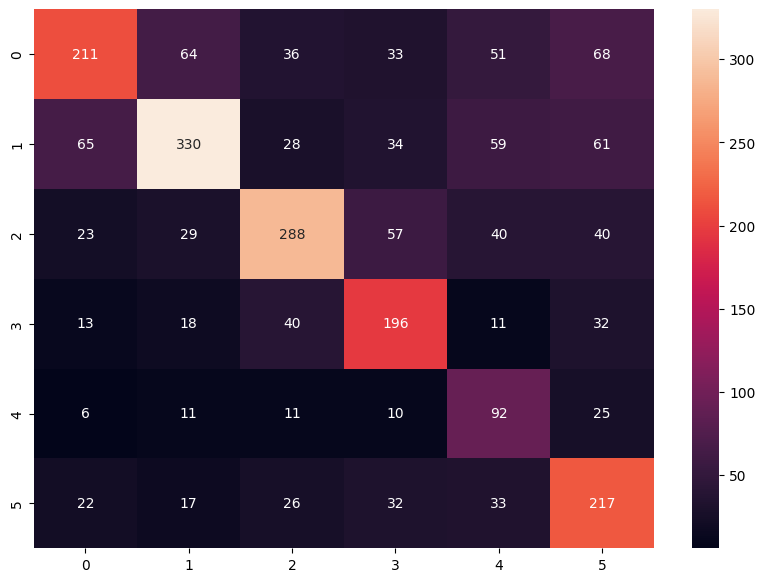

In [ ]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
#Representamos las predicciones de manera visual para su mayor comprensión

# Pintamos la matriz de confusión de TF
array_tf = metrics.confusion_matrix(y_test, predicted_tf)
df_cm_tf = pd.DataFrame(array_tf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tf, annot=True, fmt="d")

# Pintamos la matriz de confusión de TFIDF
array_tfidf = metrics.confusion_matrix(y_test, predicted_tfidf)
df_cm_tfidf = pd.DataFrame(array_tfidf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tfidf, annot=True, fmt="d")

# Pintamos la matriz de confusión de BM25
array_bm25 = metrics.confusion_matrix(y_test, predicted_bm25)
df_cm_bm25 = pd.DataFrame(array_bm25)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_bm25, annot=True, fmt="d")

## Regresión logística

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
import numpy as np
from sklearn import metrics
# Pipeline Logistic Regression con TF
clf_lr_tf = Pipeline([
    ('vect', CountVectorizer()),
    ('tf', TfidfTransformer(use_idf=False)),
    ('clf', LogisticRegression(random_state=0, solver='lbfgs')),
])

# Pipeline Logistic Regression con TF-IDF
clf_lr_tfidf = Pipeline([
    ('vect', CountVectorizer()),
    ('tfidf', TfidfTransformer(use_idf=True)),
    ('clf', LogisticRegression(random_state=0, solver='lbfgs')),
])

# Pipeline Logistic Regression con BM25
clf_lr_bm25 = Pipeline([
    ('vect', CountVectorizer()),
    ('bm25', BM25Transformer(k=1.2, b=0.5)),
    ('clf', LogisticRegression(random_state=0, solver='lbfgs')),
])

# Entrenamiento
clf_lr_tf.fit(x_train, y_train)
clf_lr_tfidf.fit(x_train, y_train)
clf_lr_bm25.fit(x_train, y_train)


Pipeline(steps=[('vect', CountVectorizer()), ('bm25', BM25Transformer(b=0.5)),
                ('clf', LogisticRegression(random_state=0))])

In [ ]:
predicted_tf = clf_lr_tf.predict(x_test)
accuracy_tf = np.mean(predicted_tf == y_test)

print("Resultados TF ----- Accuracy:", accuracy_tf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tf))

# Evaluamos el TFIDF
predicted_tfidf = clf_lr_tfidf.predict(x_test)
accuracy_tfidf = np.mean(predicted_tfidf == y_test)

print("Resultados TFIDF ----- Accuracy:", accuracy_tfidf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tfidf))

# Evaluamos el BM25
predicted_bm25 = clf_lr_bm25.predict(x_test)
accuracy_bm25 = np.mean(predicted_bm25 == y_test)

print("Resultados BM25 ----- Accuracy:", accuracy_bm25)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_bm25))

Resultados TF ----- Accuracy: 0.4753112924001717
                  precision    recall  f1-score   support

      FortNiteBR       0.53      0.33      0.41       463
       eldenring       0.70      0.44      0.54       577
             nba       0.56      0.51      0.53       477
          soccer       0.42      0.57      0.49       310
unpopularopinion       0.23      0.57      0.33       155
  wallstreetbets       0.43      0.56      0.48       347

        accuracy                           0.48      2329
       macro avg       0.48      0.50      0.46      2329
    weighted avg       0.53      0.48      0.48      2329

Resultados TFIDF ----- Accuracy: 0.5401459854014599
                  precision    recall  f1-score   support

      FortNiteBR       0.60      0.40      0.48       463
       eldenring       0.75      0.52      0.61       577
             nba       0.64      0.59      0.61       477
          soccer       0.49      0.63      0.55       310
unpopularopinion       0.

### Para este caso seguimos obteniendo mejores resultado tanto para TF-IDF como para BM25 con un 54% de accuracy, pero está por debajo de la accuracy conseguida con SVM

<Axes: >

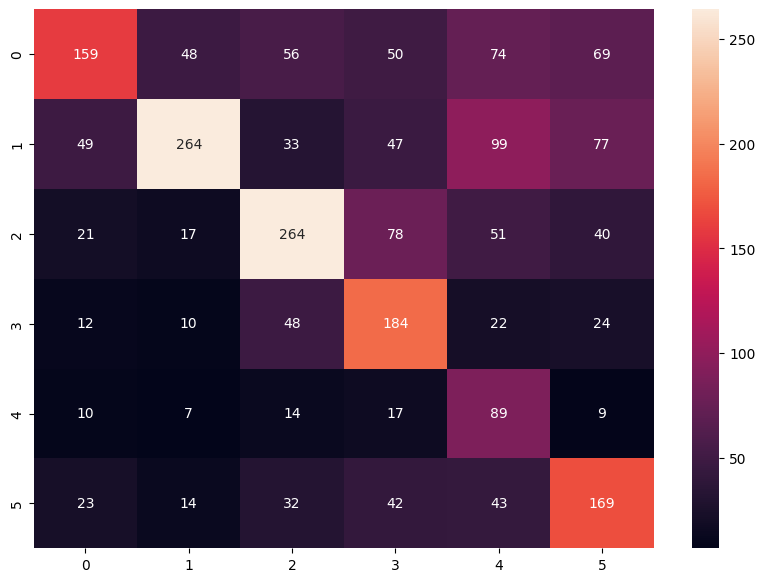

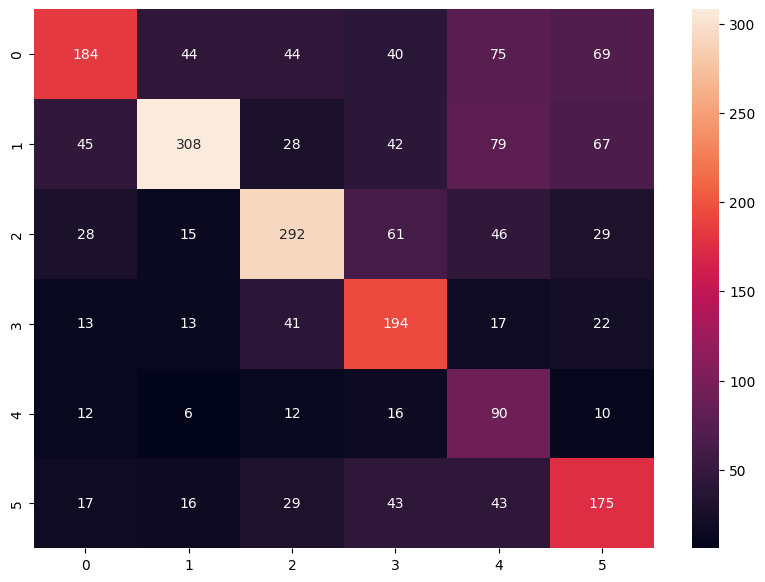

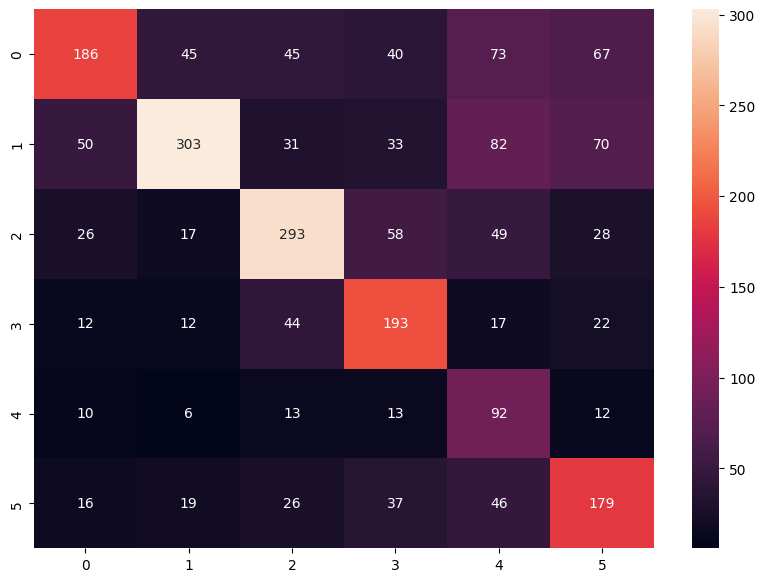

In [ ]:
# Pintamos la matriz de confusión de TF
array_tf = metrics.confusion_matrix(y_test, predicted_tf)
df_cm_tf = pd.DataFrame(array_tf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tf, annot=True, fmt="d")

# Pintamos la matriz de confusión de TFIDF
array_tfidf = metrics.confusion_matrix(y_test, predicted_tfidf)
df_cm_tfidf = pd.DataFrame(array_tfidf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tfidf, annot=True, fmt="d")

# Pintamos la matriz de confusión de BM25
array_bm25 = metrics.confusion_matrix(y_test, predicted_bm25)
df_cm_bm25 = pd.DataFrame(array_bm25)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_bm25, annot=True, fmt="d")

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
import numpy as np
from sklearn import metrics

# Pipeline Random Forest con TF
clf_rf_tf = Pipeline([
    ('vect', CountVectorizer()),
    ('tf', TfidfTransformer(use_idf=False)),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=0)),
])


# Pipeline Random Forest con TF-IDF
clf_rf_tfidf = Pipeline([
    ('vect', CountVectorizer()),
    ('tfidf', TfidfTransformer(use_idf=True)),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=0)),
])

# Pipeline Random Forest con BM25
clf_rf_bm25 = Pipeline([
    ('vect', CountVectorizer()),
    ('bm25', BM25Transformer(k=1.2, b=0.5)),
    ('clf', RandomForestClassifier(n_estimators=100, random_state=0)),
])

# Entrenamiento
clf_rf_tf.fit(x_train, y_train)
clf_rf_tfidf.fit(x_train, y_train)
clf_rf_bm25.fit(x_train, y_train)

Pipeline(steps=[('vect', CountVectorizer()), ('bm25', BM25Transformer(b=0.5)),
                ('clf', RandomForestClassifier(random_state=0))])

In [ ]:
predicted_tf = clf_rf_tf.predict(x_test)
accuracy_tf = np.mean(predicted_tf == y_test)

print("Resultados TF ----- Accuracy:", accuracy_tf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tf))

# Evaluamos el TFIDF
predicted_tfidf = clf_rf_tfidf.predict(x_test)
accuracy_tfidf = np.mean(predicted_tfidf == y_test)

print("Resultados TFIDF ----- Accuracy:", accuracy_tfidf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_tfidf))

# Evaluamos el BM25
predicted_bm25 = clf_rf_bm25.predict(x_test)
accuracy_bm25 = np.mean(predicted_bm25 == y_test)

print("Resultados BM25 ----- Accuracy:", accuracy_bm25)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_bm25))

Resultados TF ----- Accuracy: 0.41501103752759383
                  precision    recall  f1-score   support

      FortNiteBR       0.52      0.24      0.33       456
       eldenring       0.67      0.34      0.45       569
             nba       0.55      0.50      0.53       471
          soccer       0.35      0.44      0.39       300
unpopularopinion       0.19      0.64      0.30       146
  wallstreetbets       0.37      0.54      0.44       323

        accuracy                           0.42      2265
       macro avg       0.44      0.45      0.41      2265
    weighted avg       0.50      0.42      0.42      2265

Resultados TFIDF ----- Accuracy: 0.40971302428256073
                  precision    recall  f1-score   support

      FortNiteBR       0.54      0.24      0.33       456
       eldenring       0.66      0.33      0.44       569
             nba       0.54      0.49      0.51       471
          soccer       0.36      0.46      0.41       300
unpopularopinion       

LA creación de un RandomFores no ha mejorado la accuracy conseguida y la ha disminuido bastante con un 42% como máximo valor, coseguido en BM25, por lo que este modelo no nos serviría

<Axes: >

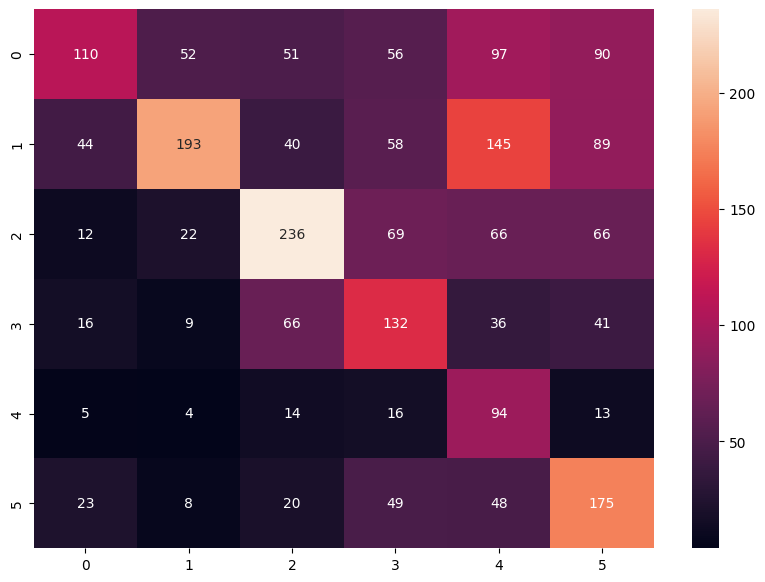

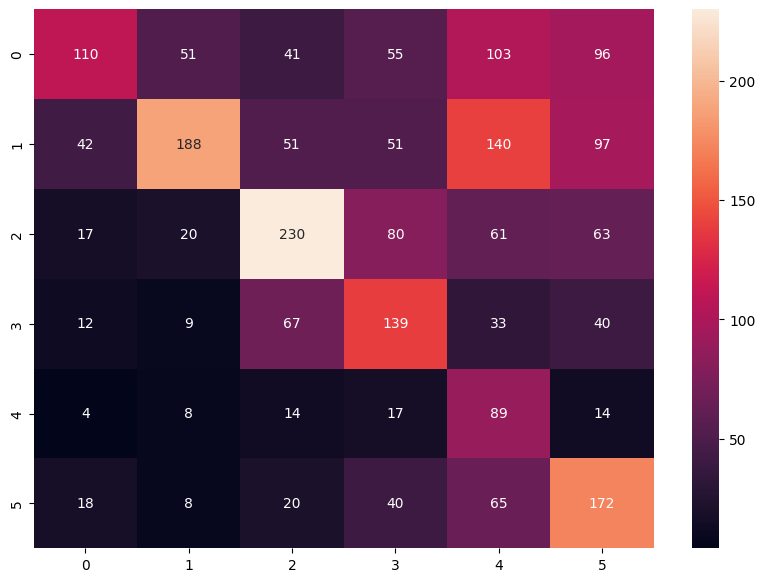

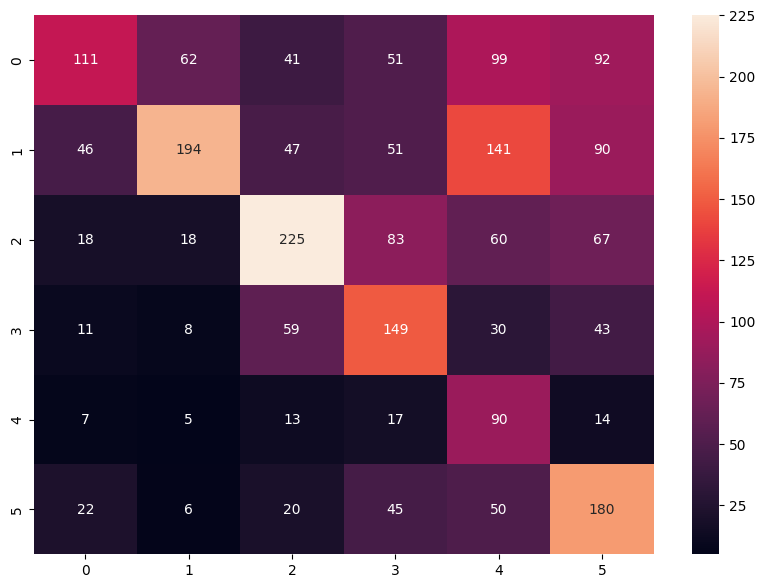

In [ ]:
# Pintamos la matriz de confusión de TF
array_tf = metrics.confusion_matrix(y_test, predicted_tf)
df_cm_tf = pd.DataFrame(array_tf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tf, annot=True, fmt="d")

# Pintamos la matriz de confusión de TFIDF
array_tfidf = metrics.confusion_matrix(y_test, predicted_tfidf)
df_cm_tfidf = pd.DataFrame(array_tfidf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_tfidf, annot=True, fmt="d")

# Pintamos la matriz de confusión de BM25
array_bm25 = metrics.confusion_matrix(y_test, predicted_bm25)
df_cm_bm25 = pd.DataFrame(array_bm25)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_bm25, annot=True, fmt="d")

# SEGUNDO ENFOQUE

## Fasttext

In [ ]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.es.300.bin.gz
!gzip -d cc.es.300.bin.gz

--2026-05-04 15:36:26--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.es.300.bin.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.4, 65.9.168.52, 65.9.168.62, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4500107671 (4.2G) [application/octet-stream]
Saving to: ‘cc.es.300.bin.gz’

cc.es.300.bin.gz    100%[===================>]   4.19G   186MB/s    in 40s     

2026-05-04 15:37:06 (108 MB/s) - ‘cc.es.300.bin.gz’ saved [4500107671/4500107671]

gzip: cc.es.300.bin already exists; do you wish to overwrite (y or n)? n
	not overwritten


In [ ]:
!pip3 install fasttext

In [ ]:
import fasttext
# Cargamos el modelo de 300 dimensiones.
ft_model = fasttext.load_model ("cc.es.300.bin")

# Calculamos los embeddings y creamos el clasificador. Usamos fasttext para convertir los textos en embeddings
fasttext_sentence_train = x_train.apply(lambda x: ft_model.get_sentence_vector(x.replace('\n', ' ')))
fasttext_sentence_test  = x_test.apply(lambda x: ft_model.get_sentence_vector(x.replace('\n', ' ')))

#Creamos el pipeline de SVM y RandomForest
clf_sentence_embeddings = LinearSVC(random_state=0, tol=1e-5). \
                               fit(fasttext_sentence_train.to_list(),
                                   y_train)


In [ ]:
clf_rf_sentence_embeddings = RandomForestClassifier(n_estimators=100, random_state=0). \
                               fit(fasttext_sentence_train.to_list(),
                                   y_train)


In [ ]:
# Evaluamos el RandomForest
predicted_rf = clf_rf_sentence_embeddings.predict(fasttext_sentence_test.to_list())
accuracy_rf = np.mean(predicted_rf == y_test)

print("Resultados Random Forest ----- Accuracy:", accuracy_rf)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_rf))

# Evaluamos el SVM
predicted_svm = clf_sentence_embeddings.predict(fasttext_sentence_test.to_list())
accuracy_svm = np.mean(predicted_svm == y_test)

print("Resultados SVM ----- Accuracy:", accuracy_svm)
from sklearn import metrics
print(metrics.classification_report(y_test, predicted_svm))

Resultados Random Forest ----- Accuracy: 0.3823399558498896
                  precision    recall  f1-score   support

      FortNiteBR       0.37      0.28      0.32       456
       eldenring       0.59      0.25      0.35       569
             nba       0.54      0.51      0.52       471
          soccer       0.37      0.45      0.40       300
unpopularopinion       0.15      0.53      0.24       146
  wallstreetbets       0.41      0.45      0.43       323

        accuracy                           0.38      2265
       macro avg       0.40      0.41      0.38      2265
    weighted avg       0.45      0.38      0.39      2265

Resultados SVM ----- Accuracy: 0.47019867549668876
                  precision    recall  f1-score   support

      FortNiteBR       0.48      0.33      0.39       456
       eldenring       0.60      0.35      0.44       569
             nba       0.61      0.58      0.60       471
          soccer       0.49      0.62      0.54       300
unpopularopinio

Para estos casos vemos que RandomForest se queda demasiado atras en cuanto a accuracy pero SVM consigue llegar hasta un 47%, sin embargo no son valores que nos puedan permitir confiar en ellos con este enfoque

<Axes: >

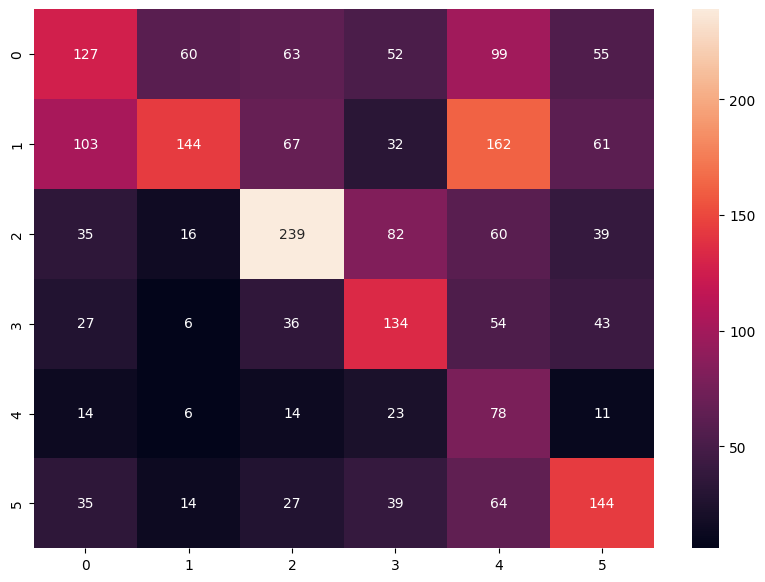

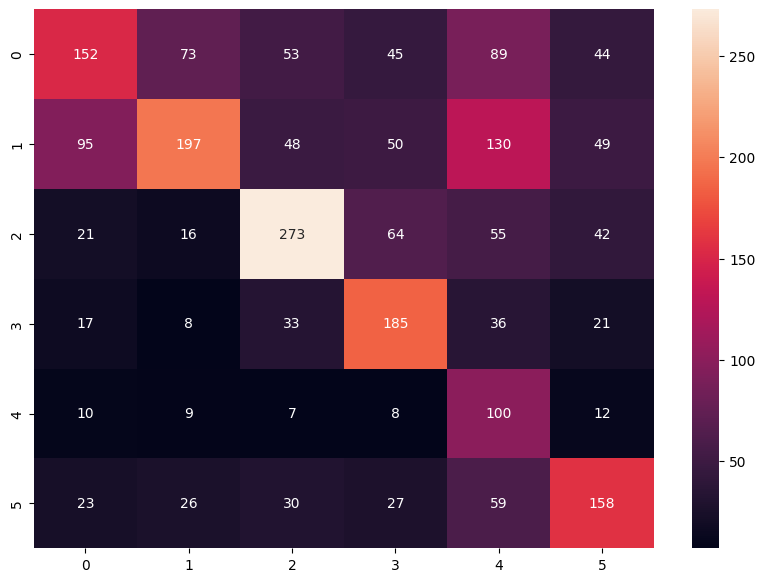

In [ ]:
# Pintamos la matriz de confusión de RandomForest
array_rf = metrics.confusion_matrix(y_test, predicted_rf)
df_cm_rf = pd.DataFrame(array_rf)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_rf, annot=True, fmt="d")

# Pintamos la matriz de confusión de SVM
array_svm = metrics.confusion_matrix(y_test, predicted_svm)
df_cm_svm = pd.DataFrame(array_svm)
plt.figure(figsize = (10,7))
sn.heatmap(df_cm_svm, annot=True, fmt="d")

# TERCER ENFOQUE

In [ ]:
!pip3 install transformers datasets torch accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.6 MB/s eta 0:00:00


In [ ]:
#import transformers
from transformers import AutoModelForSequenceClassification

from transformers import AutoTokenizer
import torch
import json

# Definición de las rutas o identificadores de los modelos preentrenados a utilizar
path_model_bert = 'bert-base-uncased'              # BERT
path_model_roberta = 'roberta-base'                   # RoBERTa

# Número total de categorías (clases) que el modelo debe clasificar
NUM_LABELS = 6

# Diccionarios para mapear índices numéricos a nombres de etiquetas (subreddits)
id2label = {0: "FortNiteBR", 1: "eldenring", 2: "nba", 3: "soccer", 4: "unpopularopinion", 5:"wallstreetbets"}
# Diccionario inverso: mapea nombres de etiquetas a sus respectivos índices numéricos
label2id = {
    "FortNiteBR": 0,
    "eldenring": 1,
    "nba": 2,
    "soccer": 3,
    "unpopularopinion": 4,
    "wallstreetbets": 5
}

# Inicialización del Tokenizer correspondiente al modelo BERT seleccionado
# use_fast=False asegura el uso de la implementación estándar en Python
tokenizer = AutoTokenizer.from_pretrained(path_model_bert, use_fast=False)

# Carga del modelo de clasificación con el número de etiquetas especificado
class_model = AutoModelForSequenceClassification.from_pretrained(path_model_bert,
                                                                 num_labels=NUM_LABELS)

# Inyección de la configuración de etiquetas personalizada dentro del objeto del modelo
class_model.config.id2label = id2label
class_model.config.label2id = label2id

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# Reservamos una parte del conjunto de entrenamiento para evaluación.
p_train = 0.80 # Porcentaje de train.
p_eval =  0.20 # Porcentaje de eval.

from sklearn.model_selection import train_test_split

# Mezclamos el dataset de manera aleatoria para poder obtener luego el conjunto
# de desarrollo "dev"
x_train_new = x_train.copy()
x_test_new = x_test.copy()
y_train_new = y_train.copy()
y_test_new = y_test.copy()


x_train_new.sample(frac=1, random_state=42)

# Para poder entrenar es necesario codificar las etiquetas como números.
# Codificamos los negativos con 0 y los positivos con 1
# según lo ya definido en los diccionarios label2id e id2label
y_train_new = y_train_new.apply(lambda x: label2id[x])
y_test_new = y_test_new.apply(lambda x : label2id[x])

x_train_new, x_eval_new, y_train_new, y_eval_new = train_test_split(
    x_train_new,
    y_train_new,
    test_size=0.2,
    random_state=42
)



## BERT

In [ ]:
import transformers
import torch
from transformers import (AutoModelForSequenceClassification,
                          TrainingArguments,
                          Trainer,
                          DataCollatorWithPadding)
import numpy as np
import json
import random
from evaluate import load
from sklearn.metrics import classification_report

# Configuración de clases y fijación de semillas para asegurar la reproducibilidad
NUM_LABELS = 6
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Cargamos el modelo para clasificación en Pytorch a través de una función para asegurar reproducibilidad
class_model = AutoModelForSequenceClassification.\
                                 from_pretrained(path_model_bert,
                                                 num_labels=NUM_LABELS)
class_model.config.id2label = id2label
class_model.config.label2id = label2id

# Clase personalizada para formatear y manejar los datos como un Dataset de PyTorch
class PLNEDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
      # Convierte los datos tokenizados y etiquetas a tensores
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)
# Carga de métrica de exactitud y función para evaluar el rendimiento del modelo
metric = load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Se obtienen las predicciones con la probabilidad más alta
    predictions = np.argmax(logits, axis=-1)
    # Muestra el informe de clasificación en consola durante la evaluación
    print(classification_report(labels, predictions, digits=6))
    return metric.compute(predictions=predictions, references=labels)

batch_train_size = 16
batch_val_size = 64
metric_name = "eval_accuracy"

# Definimos algunos training arguments como el tamaño del bach_size
training_args = transformers.TrainingArguments (
  fp16=True, # Uso de precisión mixta para acelerar
  output_dir = './results',
  num_train_epochs=3,
  eval_strategy="epoch",# Evalúa al final de cada época
  save_strategy="epoch",# Guarda checkpoint en cada época
  per_device_train_batch_size = batch_train_size,
  per_device_eval_batch_size = batch_val_size,

  # Seleccina el mejor modelo según esta métrica
  metric_for_best_model=metric_name,

  # Almacena el número de checkpoints
  save_total_limit=1,

  # Carga el mejor modelo al final
  load_best_model_at_end=True,

  # Desactiva wandb
  report_to="none",
  dataloader_pin_memory       = False,
  dataloader_num_workers      = 4,
)

# Tokenización de los textos (truncando si exceden el límite del modelo)
tokenized_train_dataset = tokenizer (x_train_new.tolist (),
                                     truncation=True)
tokenized_eval_dataset = tokenizer (x_eval_new.tolist (),
                                    truncation=True)
tokenized_test_dataset = tokenizer (x_test_new.tolist (),
                                    truncation=True)

# Como antes, las etiquetas deben ser numéricas para poder entrenar.
# Preparamos los 3 datasets para hacer el finetuning
train_dataset = PLNEDataset (tokenized_train_dataset, y_train_new.tolist())
eval_dataset = PLNEDataset (tokenized_eval_dataset, y_eval_new.tolist())
test_dataset = PLNEDataset (tokenized_test_dataset, y_test_new.tolist())

# Usamos el DataCollator para padding dinámico
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Inicialización de la clase Trainer que orquesta el bucle de entrenamiento
trainer = Trainer (
    model = class_model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset = eval_dataset,
    compute_metrics = compute_metrics,
    data_collator=data_collator
)
trainer.train()

# Guardamos el modelo reentrenado
modelo ='modeloReentrenadoPytorch'
trainer.save_model (modelo)
tokenizer.save_pretrained (modelo)

print ("PREDICCIONES SOBRE TEST")
predictions = trainer.predict (test_dataset)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.838680,0.705271
2,0.946124,0.785158,0.744618
3,0.338892,0.899067,0.752784


              precision    recall  f1-score   support

           0   0.737805  0.555046  0.633508       218
           1   0.772727  0.601010  0.676136       198
           2   0.747619  0.744076  0.745843       211
           3   0.861635  0.608889  0.713542       225
           4   0.641558  0.888489  0.745098       278
           5   0.614545  0.778802  0.686992       217

    accuracy                       0.705271      1347
   macro avg   0.729315  0.696052  0.700187      1347
weighted avg   0.725439  0.705271  0.702386      1347



...

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

PREDICCIONES SOBRE TEST


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


              precision    recall  f1-score   support

           0   0.653409  0.504386  0.569307       456
           1   0.725714  0.669596  0.696527       569
           2   0.757238  0.721868  0.739130       471
           3   0.626781  0.733333  0.675883       300
           4   0.439130  0.691781  0.537234       146
           5   0.636872  0.705882  0.669604       323

    accuracy                       0.662252      2265
   macro avg   0.639857  0.671141  0.647947      2265
weighted avg   0.673467  0.662252  0.662932      2265



Debido a la complejidad tanto en el entrenamiento como de parametro que conlleva este modelo el accuracy obtenido ha aumenta hasta llegar a un 66% quedandose por ahora como el mejor modelo posible para clasificación de textos

## ROBERTA

In [ ]:
# Cargamos el Tokenizer
tokenizer = AutoTokenizer.from_pretrained(path_model_roberta, use_fast=False)

# Carga del modelo RoBERTa preentrenado y configuración de sus etiquetas
class_model = AutoModelForSequenceClassification.from_pretrained(path_model_roberta,
                                                                 num_labels=NUM_LABELS)
class_model.config.id2label = id2label
class_model.config.label2id = label2id

x_train_new = x_train.copy()
x_test_new = x_test.copy()
y_train_new = y_train.copy()
y_test_new = y_test.copy()

# Conversión de las etiquetas (texto) a sus respectivos IDs numéricos
y_train_new = y_train_new.apply(lambda x: label2id[x])
y_test_new = y_test_new.apply(lambda x : label2id[x])

x_train_new, x_eval_new, y_train_new, y_eval_new = train_test_split(
    x_train_new,
    y_train_new,
    test_size=0.2,
    random_state=42
)

# Tokenización de los conjuntos de datos, aplicando truncamiento para textos largos
tokenized_train_dataset = tokenizer (x_train_new.tolist (),
                                     truncation=True)
tokenized_eval_dataset = tokenizer (x_eval_new.tolist (),
                                    truncation=True)
tokenized_test_dataset = tokenizer (x_test_new.tolist (),
                                    truncation=True)

# Como antes, las etiquetas deben ser numéricas para poder entrenar.
# Preparamos los 3 datasets para hacer el finetuning
train_dataset = PLNEDataset (tokenized_train_dataset, y_train_new.tolist())
eval_dataset = PLNEDataset (tokenized_eval_dataset, y_eval_new.tolist())
test_dataset = PLNEDataset (tokenized_test_dataset, y_test_new.tolist())

# Usamos el DataCollator para padding dinámico
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Inicialización del Trainer con el modelo, argumentos y los conjuntos de datos listos
trainer = Trainer (
    model = class_model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset = eval_dataset,
    compute_metrics = compute_metrics,
    data_collator=data_collator
)

trainer.train()

# Salvamos el modelo reentrenado
modelo ='modeloReentrenadoPytorch'
trainer.save_model (modelo)
tokenizer.save_pretrained (modelo)

print ("PREDICCIONES SOBRE TEST")
predictions = trainer.predict (test_dataset)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

PREDICCIONES SOBRE TEST


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


              precision    recall  f1-score   support

           0   0.602899  0.456140  0.519351       456
           1   0.672447  0.613357  0.641544       569
           2   0.741667  0.755839  0.748686       471
           3   0.631884  0.726667  0.675969       300
           4   0.437751  0.746575  0.551899       146
           5   0.675841  0.684211  0.680000       323

    accuracy                       0.645033      2265
   macro avg   0.627081  0.663798  0.636241      2265
weighted avg   0.652822  0.645033  0.643488      2265



Este modelo en comparación a los modelos obtenidos en los enfoques anteriores es muy bueno gracias a que llega a un 64%, pero el modelo BERT sigue siendo el mejor

# EJERCICIO 3. Busqueda de hilos similares

In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

subreddit_list = [result_elden_corregido, result_fortnite_corregido, result_walstreet_corregido, result_unpopular_corregido, result_nba_corregido, result_soccer_corregido]
data = []

for subreddit in subreddit_list:
  etiqueta_subreddit = subreddit.get("subreddits_procesados")

  for submission in subreddit.get("submissions", []):
      id = submission.get("id")
      title = submission.get("title_preprocessed") #Guardamos el titulo del hilo para luego poder representar la solución por este texto
      data_sub = ""
      for comment in submission.get("comments", []):
          body = comment.get("body_preprocessed")
          author = comment.get("author")

          # Filtramos el ruido: AutoModerator y comentarios borrados
          if body and body != "[removed]" and author != "AutoModerator":
              data_sub = data_sub + " " + body
      #Guardamos para cada hilo el contenido (id, comentarios, titulo, subreddit)
      data.append({
          "id": id,
          "body": data_sub,
          "name_submission": title,
          "subreddit": etiqueta_subreddit
      })

In [ ]:
import fasttext
ft_model = fasttext.load_model ("cc.es.300.bin")

In [ ]:
#Creamos los dataframes de los distintos modelos que evaluaremos
df_hilos = pd.DataFrame(data)
df_mml = df_hilos.copy()
df_mpnet = df_hilos.copy()
df_l6 = df_hilos.copy()

## Fasttext

In [ ]:
df_hilos['embedding'] = df_hilos['body'].apply(
    lambda x: ft_model.get_sentence_vector(x.replace('\n', ' '))
)

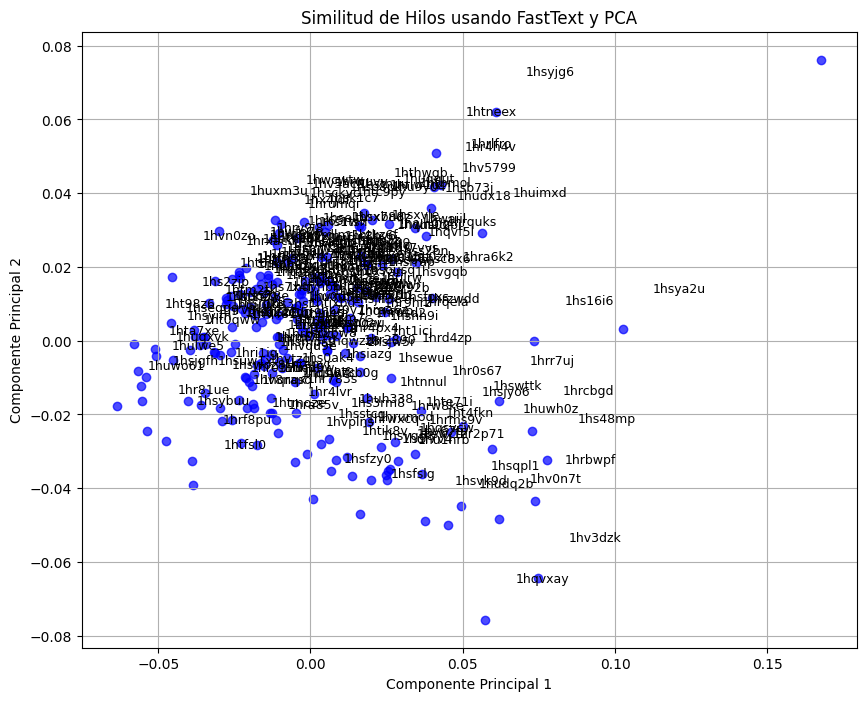

In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
# Convertir a matriz numpy para scikit-learn
matriz_embeddings = np.stack(df_hilos['embedding'].values)

# Calcular similitud entre hilos
matriz_similitud = cosine_similarity(matriz_embeddings)

# Reducción a 2D y Visualización
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(matriz_embeddings)

plt.figure(figsize=(10, 8))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.7, c='blue')

# Etiquetar cada punto con su ID de hilo para identificar cuáles no encajan
for i, txt in enumerate(df_hilos['id']):
    plt.annotate(txt, (embeddings_2d[i, 0] + 0.01, embeddings_2d[i, 1] + 0.01), fontsize=9)

plt.title("Similitud de Hilos usando FastText y PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.grid(True)
plt.show()

In [ ]:
# Reemplazamos la diagonal con 0 para no comparar un hilo consigo mismo
np.fill_diagonal(matriz_similitud, 0)

# Obtenemos los índices ordenados de mayor a menor similitud
indices_planos = np.argsort(matriz_similitud, axis=None)[::-1]

print("Los pares de hilos más parecidos entre sí son:")
pares_vistos = set()

# Recorremos los resultados para mostrar el Top 5
for idx in indices_planos:
    i, j = np.unravel_index(idx, matriz_similitud.shape)

    # Evitamos mostrar duplicados inversos como (0,1) y (1,0)
    if (i, j) not in pares_vistos and (j, i) not in pares_vistos:
        pares_vistos.add((i, j))
        hilo_1 = df_hilos['name_submission'].iloc[i]
        hilo_2 = df_hilos['name_submission'].iloc[j]
        similitud = matriz_similitud[i, j]

        print(f"Hilo '{hilo_1}' y Hilo '{hilo_2}' -> Similitud: {similitud:.4f}")

        # Detenerse tras mostrar los 5 más similares
        if len(pares_vistos) >= 5:
            break

Los pares de hilos más parecidos entre sí son:
Hilo '15 hours into my first playthrough and I can't beat this guy without summoning some wolves. Am I really bad? Haha ' y Hilo 'Finally giving it a go,never played a souls game how fucked am I?' -> Similitud: 0.9965
Hilo 'According to Sport, Real Madrid ar ready to table huge World-Record bid for centre-back in summer after talks with France star's entourage ' y Hilo 'Daily Discussion' -> Similitud: 0.9957
Hilo 'According to Sport, Real Madrid ar ready to table huge World-Record bid for centre-back in summer after talks with France star's entourage ' y Hilo '[Joyce]:Real Madrid consider second January bid for Trent Alexander-Arnold' -> Similitud: 0.9956
Hilo 'In 2012, Mohamed Salah had to beg on TV with an Al Mokawloon official to get a move to FC Basel. A reminder of why so few Egyptian players make it to Europe: even when they want to, it’s almost impossible.' y Hilo 'Daily Discussion' -> Similitud: 0.9956
Hilo '[Di Marzio] Juventus ha

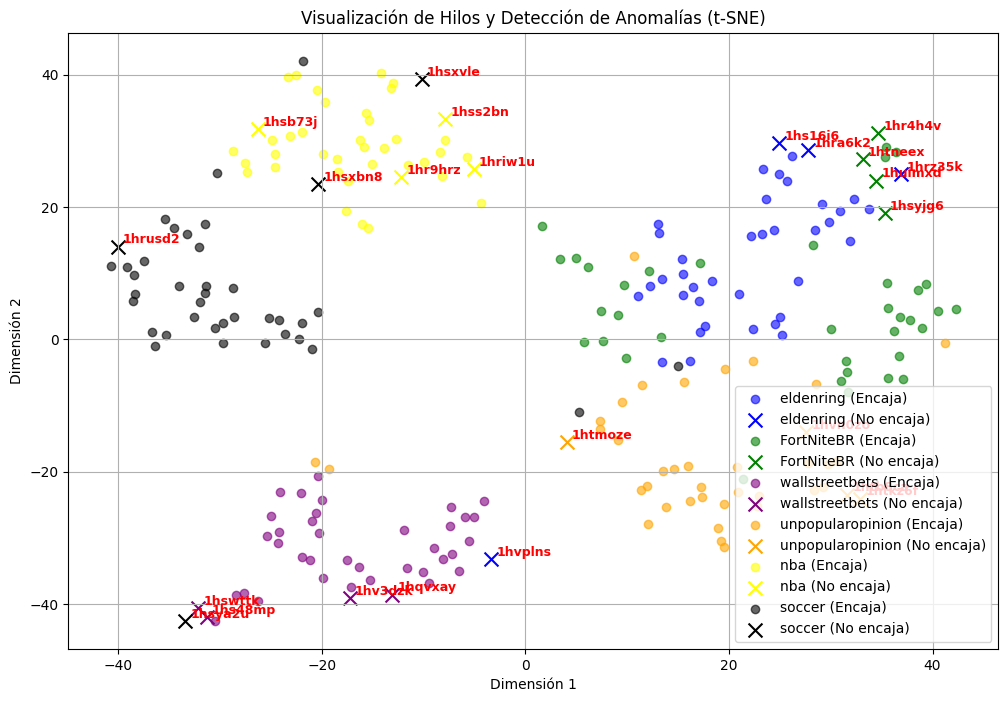

In [ ]:
from sklearn.manifold import TSNE
# Detectar qué hilos no encajan con SU subreddit
df_hilos['similitud_centroide'] = 0.0
df_hilos['encaja'] = True

subreddits = df_hilos['subreddit'].unique()

for sub in subreddits:
    # Filtrar los hilos que pertenecen a este subreddit
    mask = df_hilos['subreddit'] == sub
    embeddings_sub = np.stack(df_hilos[mask]['embedding'].values)

    # Calcular el centroide (el "hilo ideal/promedio" de este subreddit)
    centroide = np.mean(embeddings_sub, axis=0).reshape(1, -1)

    # Medir la similitud de cada hilo con su centroide
    similitudes = cosine_similarity(embeddings_sub, centroide).flatten()
    df_hilos.loc[mask, 'similitud_centroide'] = similitudes

    # Consideramos que el 10% con menor similitud son los que "no encajan" (outliers)
    umbral = np.percentile(similitudes, 10)
    df_hilos.loc[mask, 'encaja'] = df_hilos.loc[mask, 'similitud_centroide'] >= umbral

matriz_total = np.stack(df_hilos['embedding'].values)
# Nota: Si tienes pocos hilos en total (ej. < 50), mantén la perplexity baja (entre 2 y 5)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
embeddings_2d = tsne.fit_transform(matriz_total)

df_hilos['x'] = embeddings_2d[:, 0]
df_hilos['y'] = embeddings_2d[:, 1]

# 5. Visualización
plt.figure(figsize=(12, 8))
colores = ['blue', 'green', 'purple', 'orange', 'yellow', 'black'] # Añade más colores si tienes muchos subreddits distintos

for i, sub in enumerate(subreddits):
    color = colores[i % len(colores)]

    # Puntos normales (SÍ encajan)
    encajan = df_hilos[(df_hilos['subreddit'] == sub) & (df_hilos['encaja'] == True)]
    plt.scatter(encajan['x'], encajan['y'], c=color, label=f'{sub} (Encaja)', alpha=0.6)

    # Anomalías (NO encajan) marcadas con una 'X' grande
    no_encajan = df_hilos[(df_hilos['subreddit'] == sub) & (df_hilos['encaja'] == False)]
    plt.scatter(no_encajan['x'], no_encajan['y'], c=color, marker='x', s=100, label=f'{sub} (No encaja)')

    # Poner el ID como etiqueta solo a los hilos que no encajan para poder identificarlos
    for _, row in no_encajan.iterrows():
        plt.annotate(row['id'], (row['x'] + 0.5, row['y'] + 0.5), fontsize=9, color='red', weight='bold')

plt.title("Visualización de Hilos y Detección de Anomalías (t-SNE)")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.legend()
plt.grid(True)
plt.show()

Vemos como para Fasttext en general guarda bien una estructura base de los temas de subreddits
Sin ambargo tiene anomalias y problemas, uno de ellos es como vemos que une demasiado subreddits que forman parte de un tema base principal como podría ser soccer y nba (deporte) o eldenring y FortNiteBR (videojuegos), creando hilos mal clasificados dentro de subreddits a los que no pertenece
Esto podría causar que para subreddits que formen parte del mismo tema la dispersión sea tan grande que se intercalen entre ellos
También vemos como para unpopularopinion que es un tema mas general no es capaz de clasificarlo y crea una dispersión mucho mayor encontrando hilos suyos por gran parte de la representación

## MiniLm L12

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
df_mml['embedding'] = df_hilos['body'].apply(
    lambda x: model.encode(x.replace('\n', ' '))
)

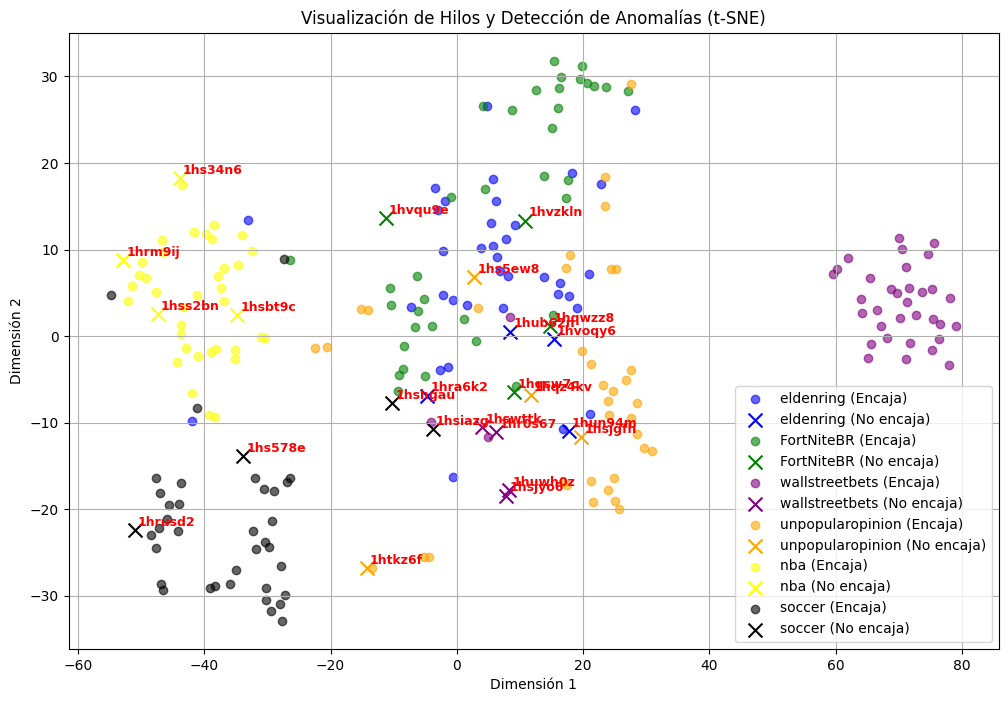

In [ ]:
from sklearn.manifold import TSNE
# Detectar qué hilos no encajan con SU subreddit
df_mml['similitud_centroide'] = 0.0
df_mml['encaja'] = True

subreddits = df_mml['subreddit'].unique()

for sub in subreddits:
    # Filtrar los hilos que pertenecen a este subreddit
    mask = df_mml['subreddit'] == sub
    embeddings_sub = np.stack(df_mml[mask]['embedding'].values)

    # Calcular el centroide (el "hilo ideal/promedio" de este subreddit)
    centroide = np.mean(embeddings_sub, axis=0).reshape(1, -1)

    # Medir la similitud de cada hilo con su centroide
    similitudes = cosine_similarity(embeddings_sub, centroide).flatten()
    df_mml.loc[mask, 'similitud_centroide'] = similitudes

    # Consideramos que el 10% con menor similitud son los que "no encajan" (outliers)
    umbral = np.percentile(similitudes, 10)
    df_mml.loc[mask, 'encaja'] = df_mml.loc[mask, 'similitud_centroide'] >= umbral

matriz_total = np.stack(df_mml['embedding'].values)
# Nota: Si tienes pocos hilos en total (ej. < 50), mantén la perplexity baja (entre 2 y 5)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
embeddings_2d = tsne.fit_transform(matriz_total)

df_mml['x'] = embeddings_2d[:, 0]
df_mml['y'] = embeddings_2d[:, 1]

# 5. Visualización
plt.figure(figsize=(12, 8))
colores = ['blue', 'green', 'purple', 'orange', 'yellow', 'black'] # Añade más colores si tienes muchos subreddits distintos

for i, sub in enumerate(subreddits):
    color = colores[i % len(colores)]

    # Puntos normales (SÍ encajan)
    encajan = df_mml[(df_mml['subreddit'] == sub) & (df_mml['encaja'] == True)]
    plt.scatter(encajan['x'], encajan['y'], c=color, label=f'{sub} (Encaja)', alpha=0.6)

    # Anomalías (NO encajan) marcadas con una 'X' grande
    no_encajan = df_mml[(df_mml['subreddit'] == sub) & (df_mml['encaja'] == False)]
    plt.scatter(no_encajan['x'], no_encajan['y'], c=color, marker='x', s=100, label=f'{sub} (No encaja)')

    # Poner el ID como etiqueta solo a los hilos que no encajan para poder identificarlos
    for _, row in no_encajan.iterrows():
        plt.annotate(row['id'], (row['x'] + 0.5, row['y'] + 0.5), fontsize=9, color='red', weight='bold')

plt.title("Visualización de Hilos y Detección de Anomalías (t-SNE)")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.legend()
plt.grid(True)
plt.show()

MiniLM L12 devide mejor los temas globales de los subreddits, ya que vemos como se estructuran en tres zonas concretas, una para cada tema global
Sin embargo, la zona equivalente a videojuegos contiene demasiada confusión siendo imposible diferenciar entre cualquiera de los tres subreddits de los que forma parte
Esto nos enseña que la zona central del dataset necesita una limpieza mas clave en el contenido y que miniLM interpreta mejor la jerga general

## MPNET

In [ ]:
model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-mpnet-base-v2')

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/402 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
df_mpnet['embedding'] = df_hilos['body'].apply(
    lambda x: model.encode(x.replace('\n', ' '))
)


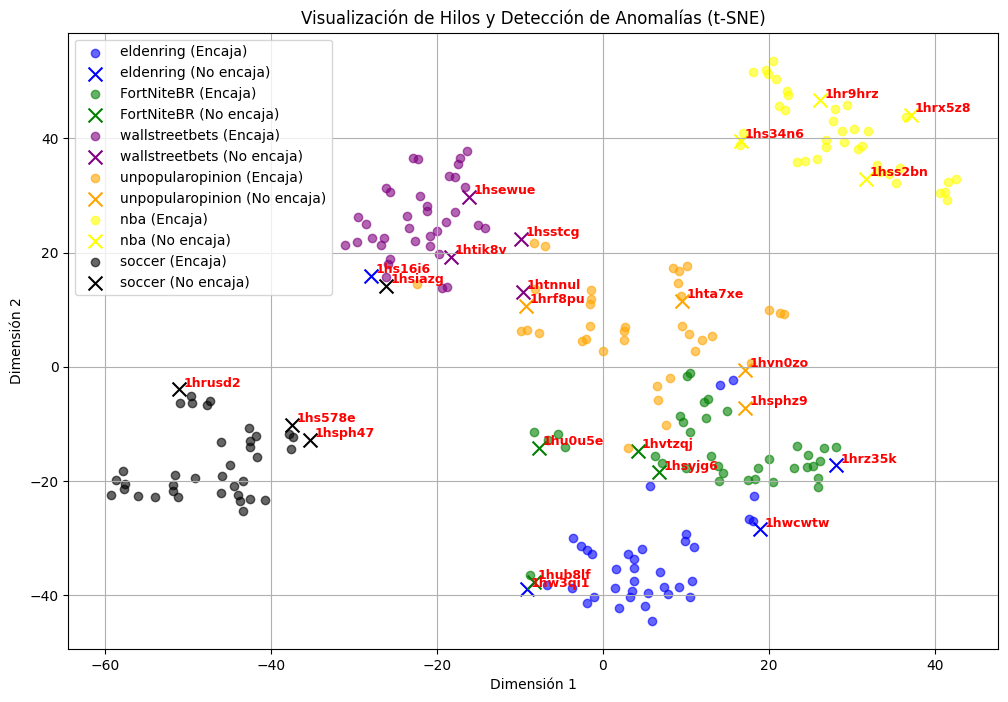

In [ ]:
from sklearn.manifold import TSNE
# Detectar qué hilos no encajan con SU subreddit
df_mpnet['similitud_centroide'] = 0.0
df_mpnet['encaja'] = True

subreddits = df_mpnet['subreddit'].unique()

for sub in subreddits:
    # Filtrar los hilos que pertenecen a este subreddit
    mask = df_mpnet['subreddit'] == sub
    embeddings_sub = np.stack(df_mpnet[mask]['embedding'].values)

    # Calcular el centroide (el "hilo ideal/promedio" de este subreddit)
    centroide = np.mean(embeddings_sub, axis=0).reshape(1, -1)

    # Medir la similitud de cada hilo con su centroide
    similitudes = cosine_similarity(embeddings_sub, centroide).flatten()
    df_mpnet.loc[mask, 'similitud_centroide'] = similitudes

    # Consideramos que el 10% con menor similitud son los que "no encajan" (outliers)
    umbral = np.percentile(similitudes, 10)
    df_mpnet.loc[mask, 'encaja'] = df_mpnet.loc[mask, 'similitud_centroide'] >= umbral

matriz_total = np.stack(df_mpnet['embedding'].values)

tsne = TSNE(n_components=2, perplexity=5, random_state=42)
embeddings_2d = tsne.fit_transform(matriz_total)

df_mpnet['x'] = embeddings_2d[:, 0]
df_mpnet['y'] = embeddings_2d[:, 1]

# 5. Visualización
plt.figure(figsize=(12, 8))
colores = ['blue', 'green', 'purple', 'orange', 'yellow', 'black']
for i, sub in enumerate(subreddits):
    color = colores[i % len(colores)]

    # Puntos normales (SÍ encajan)
    encajan = df_mpnet[(df_mpnet['subreddit'] == sub) & (df_mpnet['encaja'] == True)]
    plt.scatter(encajan['x'], encajan['y'], c=color, label=f'{sub} (Encaja)', alpha=0.6)

    # Anomalías (NO encajan) marcadas con una 'X' grande
    no_encajan = df_mpnet[(df_mpnet['subreddit'] == sub) & (df_mpnet['encaja'] == False)]
    plt.scatter(no_encajan['x'], no_encajan['y'], c=color, marker='x', s=100, label=f'{sub} (No encaja)')

    # Poner el ID como etiqueta solo a los hilos que no encajan para poder identificarlos
    for _, row in no_encajan.iterrows():
        plt.annotate(row['id'], (row['x'] + 0.5, row['y'] + 0.5), fontsize=9, color='red', weight='bold')

plt.title("Visualización de Hilos y Detección de Anomalías (t-SNE)")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.legend()
plt.grid(True)
plt.show()

Con MPNet nos encontramos un mejor equilibrio en comparación a las anteriores,
Es capaz separar de mejor manera los distintos subreddits ya que vemos mejor diferencia entre cualquiera de los seis temas
Los valores atipicos forman parte de la frontera de los clusters, por lo que este modelo no crea mucha dispersión en sus hilos
sin embargo, vemos como temas muy parecidos como son nba y soccer que forman parte de un tema central que es deporte están muy separados